,RMS (Energía),ZCR (Cruces por cero),Centroide Espectral (Hz),Ancho de Banda (Hz),MFCC_1 (Media),MFCC_2 (Media)
Género,,,,,,
classical,0.0362,0.0982,1505.4,1559.2,-268.22,135.68
jazz,0.0467,0.0784,1503.9,1754.3,-252.10,137.90
hiphop,0.1252,0.1473,2668.0,2351.3,-80.93,84.78
metal,0.1161,0.1830,3274.5,2722.5,-52.94,50.09


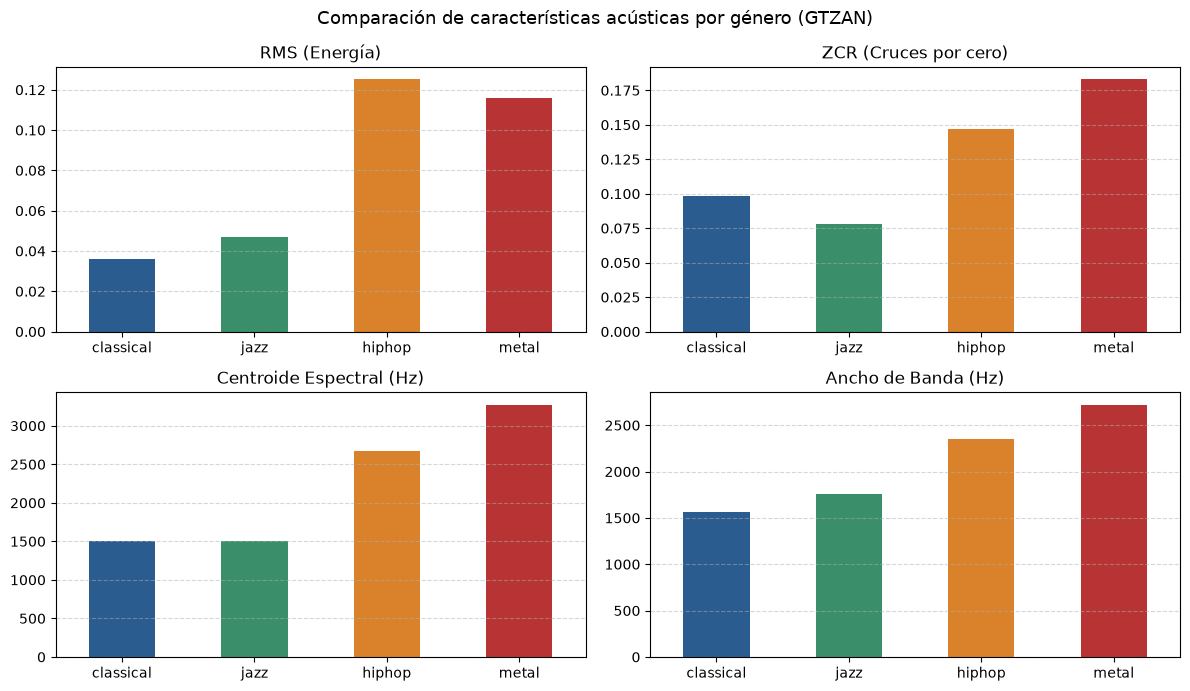

In [1]:
import librosa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA_ROOT = Path("../data/gtzan")

# Seleccionamos 4 ejemplos pedagógicos con texturas acústicas muy distintas
SAMPLES = {
    "classical": DATA_ROOT / "classical/classical.00000.wav",
    "jazz":      DATA_ROOT / "jazz/jazz.00000.wav",
    "hiphop":    DATA_ROOT / "hiphop/hiphop.00000.wav",
    "metal":     DATA_ROOT / "metal/metal.00000.wav",
}

def extract_features(path):
    y, sr = librosa.load(path, sr=22050)
    
    rms = np.mean(librosa.feature.rms(y=y))
    zcr = np.mean(librosa.feature.zero_crossing_rate(y=y))
    centroid = np.mean(librosa.feature.spectral_centroid(y=y, sr=sr))
    bandwidth = np.mean(librosa.feature.spectral_bandwidth(y=y, sr=sr))
    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    
    features = {
        "RMS (Energía)": round(float(rms), 4),
        "ZCR (Cruces por cero)": round(float(zcr), 4),
        "Centroide Espectral (Hz)": round(float(centroid), 1),
        "Ancho de Banda (Hz)": round(float(bandwidth), 1),
        "MFCC_1 (Media)": round(float(np.mean(mfccs[0])), 2),
        "MFCC_2 (Media)": round(float(np.mean(mfccs[1])), 2),
    }
    return features, mfccs

rows = []
mfcc_dict = {}

for genre, path in SAMPLES.items():
    feats, mfccs = extract_features(path)
    feats["Género"] = genre
    rows.append(feats)
    mfcc_dict[genre] = np.mean(mfccs, axis=1)

df_features = pd.DataFrame(rows).set_index("Género")
display(df_features)

# Gráfico comparativo de las 4 métricas escalares principales
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
metrics = [
    "RMS (Energía)",
    "ZCR (Cruces por cero)",
    "Centroide Espectral (Hz)",
    "Ancho de Banda (Hz)"
]
colors = ["#2b5c8f", "#3a8f6a", "#d9822b", "#b83333"]

for ax, metric in zip(axes.flat, metrics):
    df_features[metric].plot(kind="bar", ax=ax, color=colors, rot=0)
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.suptitle("Comparación de características acústicas por género (GTZAN)", fontsize=13)
plt.tight_layout()
plt.show()

[CLASSICAL] Frames con F0 detectada: 61.7%


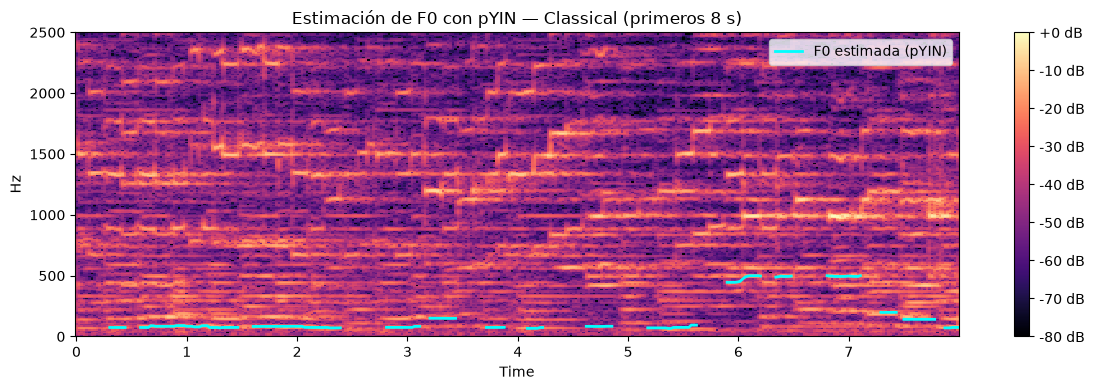

[METAL] Frames con F0 detectada: 66.4%


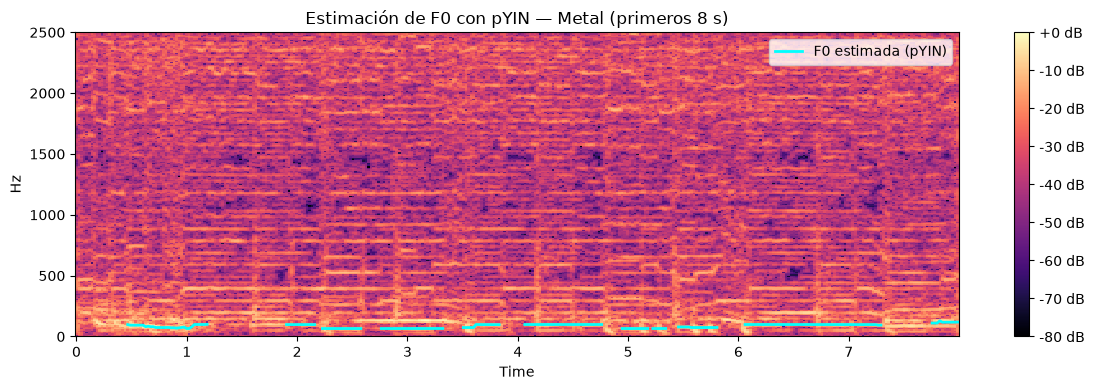

In [2]:
import librosa.display

def test_pyin(genre, path, duration=8.0):
    y, sr = librosa.load(path, sr=22050, duration=duration)
    
    f0, voiced_flag, voiced_prob = librosa.pyin(
        y,
        fmin=librosa.note_to_hz("C2"),
        fmax=librosa.note_to_hz("C7"),
        sr=sr
    )
    times = librosa.times_like(f0, sr=sr)
    
    D = librosa.stft(y)
    S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)
    
    voiced_pct = 100 * np.mean(voiced_flag)
    print(f"[{genre.upper()}] Frames con F0 detectada: {voiced_pct:.1f}%")
    
    plt.figure(figsize=(12, 4))
    librosa.display.specshow(S_db, sr=sr, x_axis="time", y_axis="linear")
    plt.plot(times, f0, color="cyan", linewidth=2, label="F0 estimada (pYIN)")
    plt.ylim(0, 2500)
    plt.colorbar(format="%+2.0f dB")
    plt.legend(loc="upper right")
    plt.title(f"Estimación de F0 con pYIN — {genre.capitalize()} (primeros {int(duration)} s)")
    plt.tight_layout()
    plt.show()

test_pyin("classical", SAMPLES["classical"])
test_pyin("metal", SAMPLES["metal"])